In [1]:
import os

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import mediapy as media
import mujoco
import numpy as np
import pandas as pd
import seaborn as sns
from mujoco import mjx
from tqdm import tqdm

from brain import gait
from brain.train import CONTROL_REPEAT, clone_gait, standing_state

In [2]:
# 1. Load your hexapod scene using standard MuJoCo
file = "../models/SELF_Hexapod/scene.xml"
mj_model = mujoco.MjModel.from_xml_path(file) #type: ignore
spec = mujoco.MjSpec.from_file(file) #type: ignore
mj_data = mujoco.MjData(mj_model) #type: ignore


model = mjx.put_model(mj_model)
data = mjx.put_data(mj_model, mj_data)
renderer = mujoco.Renderer(mj_model)

""

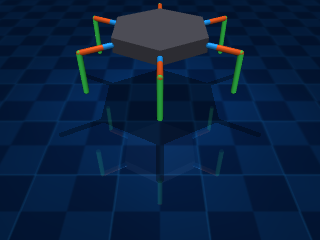

In [3]:
# viz scene and model
mujoco.mj_forward(mj_model, mj_data) #type: ignore
renderer.update_scene(mj_data, camera="fixed_cam")
media.show_image(renderer.render())

In [4]:
@jax.jit
def differentiable_simulation_step(current_state, actions):
    """
    Takes the current MJX data state and an action vector, 
    steps the physics engine natively on the GPU, and returns the next state.
    """
    # Inject actions into the position actuators (18 DOF)
    state_with_action = current_state.replace(ctrl=actions)
    
    # Step the solver forward (completely differentiable!)
    next_state = mjx.step(model, state_with_action)
    return next_state

def calculate_loss(actions, initial_state):
    # Predict the next physics frame
    predicted_state = differentiable_simulation_step(initial_state, actions)
    
    # Target: We want the torso height (qpos[2]) to stay at exactly 0.35 meters
    # (Updated for the new 3-DOF hexapod geometry)
    torso_height = predicted_state.qpos[2]
    loss = jnp.square(torso_height - 0.35)
    return loss

In [5]:
grad_loss_fn = jax.grad(calculate_loss)

settled = mujoco.MjData(mj_model)
for _ in range(500):
    mujoco.mj_step(mj_model, settled)
settled_state = mjx.put_data(mj_model, settled)

# FIX: We now have (coxa, femur, tibia) per leg. 3 joints * 6 legs = 18 actions.
# Let's test with 0.0 for yaw, 0.3 for femur lift, and -0.1 for tibia reach.
test_actions = jnp.array([0.0, 0.3, -0.1] * 6)  
analytical_gradients = grad_loss_fn(test_actions, settled_state)

print(f"torso height {settled.qpos[2]:.3f} m, {settled.ncon} feet on the floor\n")
for i, g in tqdm(enumerate(analytical_gradients), total=len(analytical_gradients)):
    name = mujoco.mj_id2name(mj_model, mujoco.mjtObj.mjOBJ_ACTUATOR, i)
    print(f"  d(height loss)/d({name:14s}) = {g:+.3e}")

torso height 0.130 m, 6 feet on the floor



100%|██████████| 18/18 [00:00<00:00, 518.40it/s]

  d(height loss)/d(act_coxa_fl   ) = -3.460e-09
  d(height loss)/d(act_femur_fl  ) = -2.348e-05
  d(height loss)/d(act_tibia_fl  ) = +2.187e-05
  d(height loss)/d(act_coxa_ml   ) = -4.805e-12
  d(height loss)/d(act_femur_ml  ) = -2.348e-05
  d(height loss)/d(act_tibia_ml  ) = +2.187e-05
  d(height loss)/d(act_coxa_bl   ) = +3.451e-09
  d(height loss)/d(act_femur_bl  ) = -2.348e-05
  d(height loss)/d(act_tibia_bl  ) = +2.187e-05
  d(height loss)/d(act_coxa_fr   ) = +3.454e-09
  d(height loss)/d(act_femur_fr  ) = -2.348e-05
  d(height loss)/d(act_tibia_fr  ) = +2.187e-05
  d(height loss)/d(act_coxa_mr   ) = +3.366e-12
  d(height loss)/d(act_femur_mr  ) = -2.348e-05
  d(height loss)/d(act_tibia_mr  ) = +2.187e-05
  d(height loss)/d(act_coxa_br   ) = -3.443e-09
  d(height loss)/d(act_femur_br  ) = -2.348e-05
  d(height loss)/d(act_tibia_br  ) = +2.187e-05


In [6]:
DURATION = 5
FRAMERATE = 60

n_steps = int(DURATION / mj_model.opt.timestep)

mujoco.mj_resetData(mj_model, mj_data)
mjx_data = mjx.put_data(mj_model, mj_data)

frames = []
action = jnp.asarray(test_actions)

while float(mjx_data.time) < DURATION:
    # Advance the MJX simulation using the specified tendon actions.
    mjx_data = differentiable_simulation_step(mjx_data, action)

    # Copy the MJX state to standard MuJoCo for rendering.
    mj_data.qpos[:] = jax.device_get(mjx_data.qpos)
    mj_data.qvel[:] = jax.device_get(mjx_data.qvel)
    mj_data.time = float(mjx_data.time)

    mujoco.mj_forward(mj_model, mj_data)

    if len(frames) < mj_data.time * FRAMERATE:
        # tracking_cam follows the torso, so the robot stays framed as it moves
        renderer.update_scene(mj_data, camera="tracking_cam")
        frames.append(renderer.render())

media.show_video(frames, fps=FRAMERATE)


This browser does not support the video tag.


## The brain

In [7]:
import brain

limits = brain.joint_limits(mj_model)
params = brain.mlp.init(
    jax.random.key(0), [brain.obs_dim(mj_model), 64, 64, mj_model.nu]
)

print("observation:", brain.obs_dim(mj_model), "-> actuators:", mj_model.nu)


@jax.jit
def brain_step(state):
    """Close the loop: state -> observation -> MLP -> joint targets -> physics."""
    ctrl = brain.act(params, state, limits)
    return mjx.step(model, state.replace(ctrl=ctrl)), ctrl


observation: 67 -> actuators: 18


In [8]:
sim_time = np.zeros(n_steps)
ncon = np.zeros(n_steps)
force = np.zeros((n_steps,3))
velocity = np.zeros((n_steps, model.nv))
penetration = np.zeros(n_steps)
acceleration = np.zeros((n_steps, model.nv))
forcetorque = np.zeros(6)

In [9]:
mujoco.mj_resetData(mj_model, mj_data)
mj_data.qvel[3:6] = 2*np.random.randn(3)
mjx_data = mjx.put_data(mj_model, mj_data)

frames, ctrl_log = [], []

while float(mjx_data.time) < DURATION:
    mjx_data, ctrl = brain_step(mjx_data)
    ctrl_log.append(jax.device_get(ctrl))
    i = int(float(mjx_data.time) / mj_model.opt.timestep)

    mj_data.qpos[:] = jax.device_get(mjx_data.qpos)
    mj_data.qvel[:] = jax.device_get(mjx_data.qvel)
    mj_data.time = float(mjx_data.time)

    mujoco.mj_resetData(mj_model, mj_data)
    mj_data.qvel[3:6] = 2 * np.random.randn(3)
    mjx_data = mjx.put_data(mj_model, mj_data)

    frames, ctrl_log = [], []

    for i in range(n_steps):
        mjx_data, ctrl = brain_step(mjx_data)
        ctrl_log.append(jax.device_get(ctrl))

        mj_data.qpos[:] = jax.device_get(mjx_data.qpos)
        mj_data.qvel[:] = jax.device_get(mjx_data.qvel)
        mj_data.time = float(mjx_data.time)

        mujoco.mj_forward(mj_model, mj_data)

        sim_time[i] = mj_data.time
        ncon[i] = mj_data.ncon
        velocity[i] = mj_data.qvel[:]
        acceleration[i] = mj_data.qacc[:]

        for j, c in enumerate(mj_data.contact):
            mujoco.mj_contactForce(mj_model, mj_data, j, forcetorque)
            force[i] += forcetorque[:3]
            penetration[i] = min(penetration[i], c.dist)

        if len(frames) < mj_data.time * FRAMERATE:
            renderer.update_scene(mj_data, camera="tracking_cam")
            frames.append(renderer.render())

    media.show_video(frames, fps=FRAMERATE)


This browser does not support the video tag.


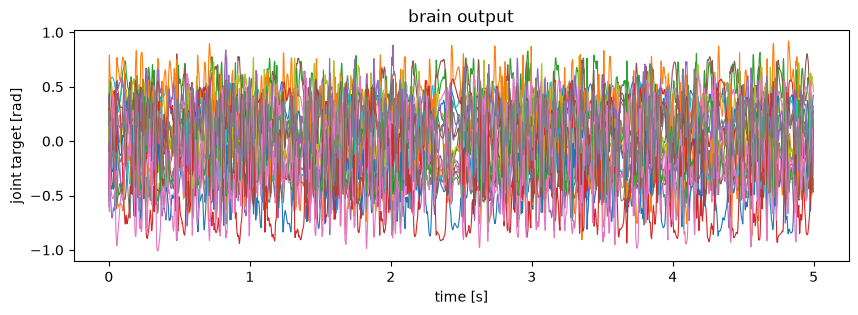

In [10]:
plt.figure(figsize=(10, 3))
plt.plot(np.arange(len(ctrl_log)) * mj_model.opt.timestep, np.array(ctrl_log), lw=0.8)
plt.xlabel("time [s]")
plt.ylabel("joint target [rad]")
plt.title("brain output")
plt.show()


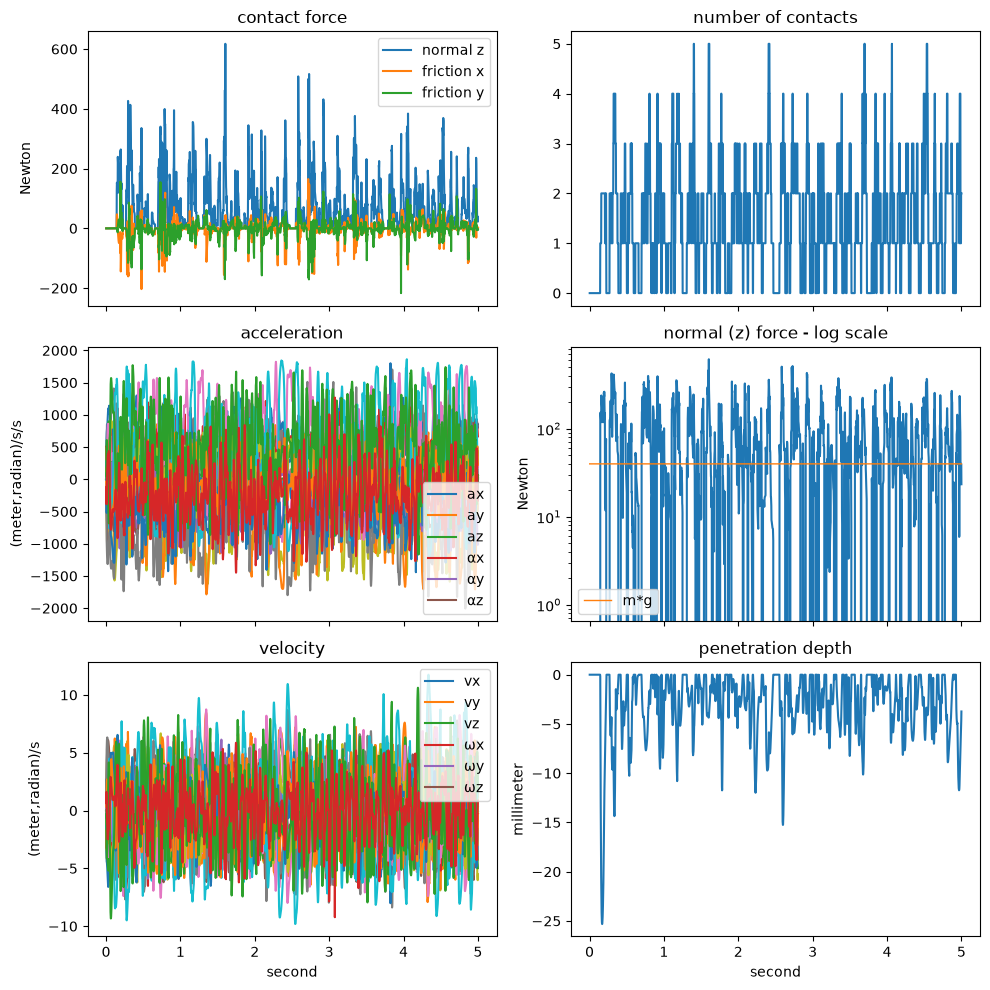

In [11]:
# plot
_, ax = plt.subplots(3, 2, sharex=True, figsize=(10, 10))

lines = ax[0,0].plot(sim_time, force)
ax[0,0].set_title('contact force')
ax[0,0].set_ylabel('Newton')
ax[0,0].legend(list(lines), ('normal z', 'friction x', 'friction y'));

ax[1,0].plot(sim_time, acceleration)
ax[1,0].set_title('acceleration')
ax[1,0].set_ylabel('(meter,radian)/s/s')
ax[1,0].legend(['ax', 'ay', 'az', 'αx', 'αy', 'αz'])

ax[2,0].plot(sim_time, velocity)
ax[2,0].set_title('velocity')
ax[2,0].set_ylabel('(meter,radian)/s')
ax[2,0].set_xlabel('second')
ax[2,0].legend(['vx', 'vy', 'vz', 'ωx', 'ωy', 'ωz'])

ax[0,1].plot(sim_time, ncon)
ax[0,1].set_title('number of contacts')
ax[0,1].set_yticks(range(6))

ax[1,1].plot(sim_time, force[:,0])
ax[1,1].set_yscale('log')
ax[1,1].set_title('normal (z) force - log scale')
ax[1,1].set_ylabel('Newton')
z_gravity = -model.opt.gravity[2]
torso_id = mujoco.mj_name2id(
    mj_model, mujoco.mjtObj.mjOBJ_BODY, "torso"
)
mg = mj_model.body_mass[torso_id] * float(z_gravity)
mg_line = ax[1,1].plot(sim_time, np.ones(n_steps)*mg, label='m*g', linewidth=1)
ax[1,1].legend()

ax[2,1].plot(sim_time, 1000*penetration)
ax[2,1].set_title('penetration depth')
ax[2,1].set_ylabel('millimeter')
ax[2,1].set_xlabel('second')

plt.tight_layout()

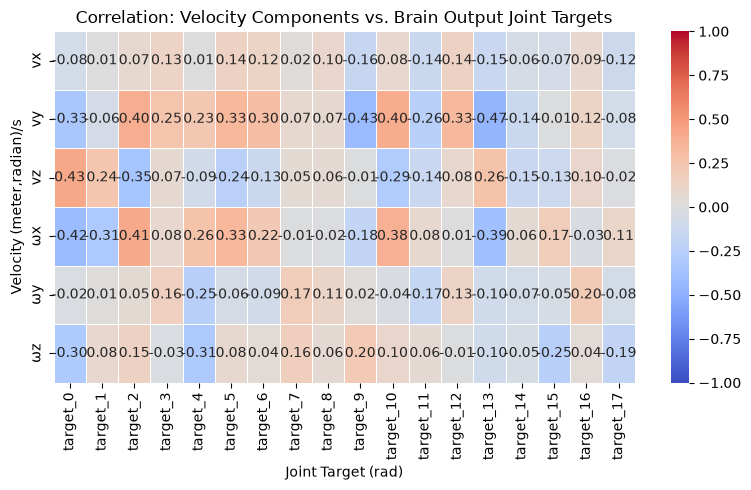

In [12]:
df_brain = pd.DataFrame(ctrl_log, columns=[f"target_{i}" for i in range(np.atleast_2d(ctrl_log).shape[1])])

velocity_labels = ["vx", "vy", "vz", "ωx", "ωy", "ωz"]
df_velocity = pd.DataFrame(velocity[:, :6], columns=velocity_labels)


df_combined = pd.concat([df_velocity, df_brain], axis=1)

corr_matrix = df_combined.corr("spearman")

brain_cols = df_brain.columns
corr_filtered = corr_matrix.loc[velocity_labels, brain_cols]

# 4. Plot the heatmap (using your layout or a new figure)
plt.figure(figsize=(8, 5))
sns.heatmap(
    corr_filtered, 
    annot=True,          # Shows the numerical correlation value in each cell
    cmap="coolwarm",     # Red for positive correlation, blue for negative correlation
    vmin=-1, vmax=1,     # Correlation bounds
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation: Velocity Components vs. Brain Output Joint Targets")
plt.ylabel("Velocity (meter,radian)/s")
plt.xlabel("Joint Target (rad)")
plt.tight_layout()
plt.show()


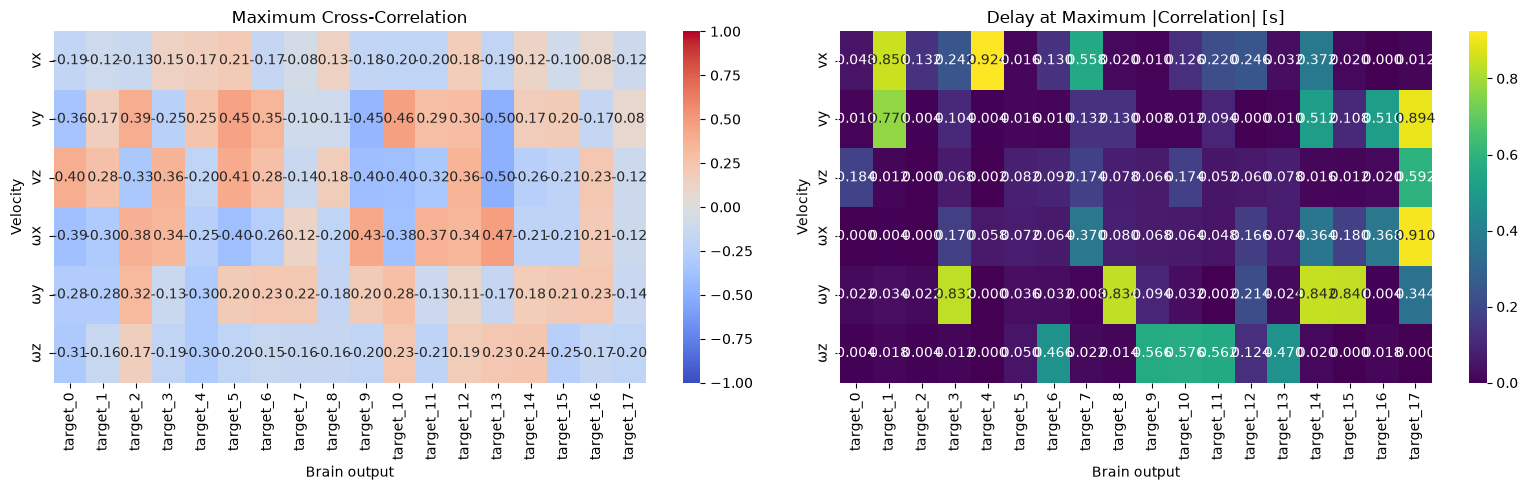

In [13]:
brain_array = np.asarray(ctrl_log)
if brain_array.ndim == 1:
    brain_array = brain_array[:, None]

n = min(len(sim_time), len(velocity), len(brain_array))
velocity_data = velocity[:n, :6]
brain_data = brain_array[:n]

# Test delays from 0 to 1 second
max_delay = 1.0
lag_steps = np.arange(0, int(max_delay / mj_model.opt.timestep) + 1)
delays = lag_steps * mj_model.opt.timestep

cross_corr = np.full(
    (len(lag_steps), len(velocity_labels), brain_data.shape[1]),
    np.nan,
)

for k, lag in enumerate(lag_steps):
    if lag == 0:
        v = velocity_data
        b = brain_data
    else:
        v = velocity_data[lag:]
        b = brain_data[:-lag]

    for i in range(v.shape[1]):
        for j in range(b.shape[1]):
            if np.std(v[:, i]) > 0 and np.std(b[:, j]) > 0:
                cross_corr[k, i, j] = np.corrcoef(
                    b[:, j], v[:, i]
                )[0, 1]

# Select the delay with the strongest absolute correlation for each pair
best_lag_idx = np.nanargmax(np.abs(cross_corr), axis=0)
best_corr = np.take_along_axis(
    cross_corr, best_lag_idx[None, :, :], axis=0
)[0]
best_delay = delays[best_lag_idx]

brain_labels = [f"target_{i}" for i in range(brain_data.shape[1])]

fig, ax = plt.subplots(1, 2, figsize=(16, 5))

sns.heatmap(
    best_corr,
    ax=ax[0],
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    xticklabels=brain_labels,
    yticklabels=velocity_labels,
)
ax[0].set_title("Maximum Cross-Correlation")
ax[0].set_xlabel("Brain output")
ax[0].set_ylabel("Velocity")

sns.heatmap(
    best_delay,
    ax=ax[1],
    annot=True,
    fmt=".3f",
    cmap="viridis",
    xticklabels=brain_labels,
    yticklabels=velocity_labels,
)
ax[1].set_title("Delay at Maximum |Correlation| [s]")
ax[1].set_xlabel("Brain output")
ax[1].set_ylabel("Velocity")

plt.tight_layout()
plt.show()

## Training

I built the analytic-policy-gradient pipeline — loss differentiated straight
through `mjx.step`, truncated BPTT, Muon — and then measured whether its
gradient is any good. On this model it is not:

| horizon | physics steps | analytic | finite-diff | rel. error |
|---|---|---|---|---|
| 1 | 10 | 4.85e-04 | 3.02e-02 | 6119% |
| 4 | 40 | -2.14e-03 | -1.59e-01 | 7310% |
| 16 | 160 | 5.86e-01 | -9.90e-01 | 269% |

Even at a **one-step horizon** the analytic gradient is 62x smaller than the
true secant. float64 does not rescue it: it moves the analytic value by three
orders of magnitude (so float32 was largely roundoff), and the finite
differences then disagree with *each other* by four orders and flip sign with
step size. That is not a precision problem, it is a non-smooth loss surface.
A foot landing one timestep earlier is a discontinuity, and contact-mode
switches dominate whatever the local slope says.

Everything else is consistent: the from-scratch velocity objective *diverges*,
and gait tracking sat flat at 0.186 for 600 epochs without ever reaching the
trivial zero-policy score of 0.110.

So `train()` (APG) stays in the codebase with that evidence recorded, and the
policy below is fitted with `clone_gait()` — same MLP, same adapter, same Muon
optimizer, supervised against the reference gait. It converges in ~17 s and
walks 1.41 m in 5 s. It does not exploit the simulator's differentiability,
which is the honest tradeoff, and is why PPO rather than APG is what people
actually ship for contact-rich locomotion.

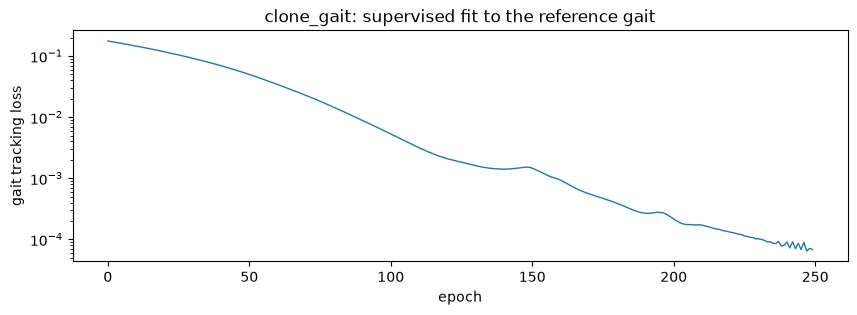

loss 0.1763 -> 0.000068


In [ ]:
trained_params, history = clone_gait(mj_model, params, jax.random.key(0), epochs=5000)

plt.figure(figsize=(10, 3))
plt.plot(history, lw=1)
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("gait tracking loss")
plt.title("clone_gait: supervised fit to the reference gait")
plt.show()

print(f"loss {history[0]:.4f} -> {history[-1]:.6f}")

In [15]:
N_CONTROL = 2000


@jax.jit
def trained_step(state):
    ctrl = brain.act(trained_params, state, limits)
    state, _ = jax.lax.scan(
        lambda s, _: (mjx.step(model, s.replace(ctrl=ctrl)), None),
        state,
        length=CONTROL_REPEAT,
    )
    return state, ctrl


start = standing_state(mj_model)
state = mjx.put_data(mj_model, start)

trained_ctrl, trained_velocity = [], []
for _ in range(N_CONTROL):
    state, ctrl = trained_step(state)
    trained_ctrl.append(jax.device_get(ctrl))
    trained_velocity.append(jax.device_get(state.qvel[:6]))

trained_ctrl = np.array(trained_ctrl)
trained_velocity = np.array(trained_velocity)
distance = float(jax.device_get(state.qpos[0])) - start.qpos[0]
print(f"trained policy walked {distance:+.3f} m in {float(state.time) - start.time:.1f} s. Speed: {distance / (float(state.time) - start.time):+.3f} m/s")


trained policy walked +8.855 m in 40.0 s. Speed: +0.221 m/s


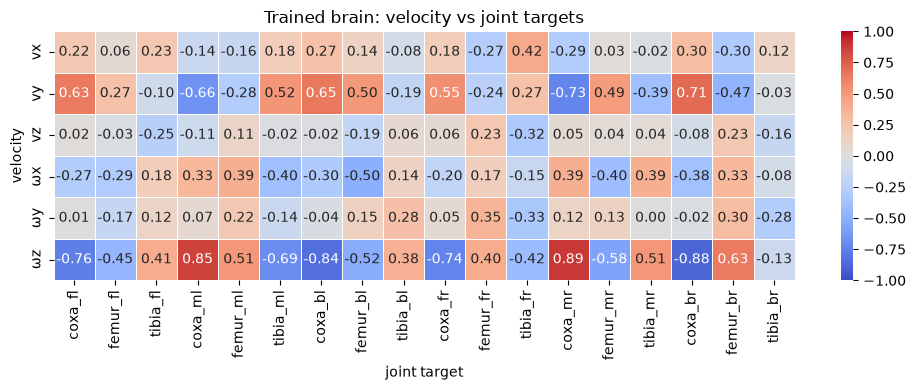

In [16]:
# Same heatmap as for the random brain, so the two are directly comparable.
actuator_names = [
    mujoco.mj_id2name(mj_model, mujoco.mjtObj.mjOBJ_ACTUATOR, i).replace("act_", "")
    for i in range(mj_model.nu)
]
df = pd.concat(
    [
        pd.DataFrame(trained_velocity, columns=velocity_labels),
        pd.DataFrame(trained_ctrl, columns=actuator_names),
    ],
    axis=1,
)
corr = df.corr("spearman").loc[velocity_labels, actuator_names]

plt.figure(figsize=(10, 4))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)
plt.title("Trained brain: velocity vs joint targets")
plt.xlabel("joint target")
plt.ylabel("velocity")
plt.tight_layout()
plt.show()

In [17]:
LANE = 0.6  # metres between the two lanes

duel = mujoco.MjSpec.from_string(
    open(file).read().replace('<include file="hexapod.xml"/>', "")
)

duel.option.integrator = mj_model.opt.integrator
duel.option.iterations = mj_model.opt.iterations
duel.option.timestep = mj_model.opt.timestep

for prefix, y in (("gait_", LANE), ("brain_", -LANE)):
    frame = duel.worldbody.add_frame(pos=[0, y, 0])
    duel.attach(
        mujoco.MjSpec.from_file("../models/SELF_Hexapod/hexapod.xml"),
        prefix=prefix,
        frame=frame,
    )

duel.body("gait_torso").add_camera(
    name="duel_cam",
    pos=[0, -(2.3 + LANE), 1.45],
    euler=[57, 0, 0],
    fovy=55,
    mode=mujoco.mjtCamLight.mjCAMLIGHT_TRACK,
)
duel_model = duel.compile()
duel_data = mujoco.MjData(duel_model)
duel_renderer = mujoco.Renderer(duel_model, 720, 1280)

# Two independent rollouts from the same standing pose.
gait_state = mjx.put_data(mj_model, standing_state(mj_model))
brain_state = mjx.put_data(mj_model, standing_state(mj_model))


@jax.jit
def gait_step(state):
    ctrl = gait.tripod(state.time)
    return jax.lax.scan(
        lambda s, _: (mjx.step(model, s.replace(ctrl=ctrl)), None),
        state,
        length=CONTROL_REPEAT,
    )[0]

In [18]:
# --- Pre-computation Lookup for CoM ---
# Look up the torso body IDs once after compiling the duel model
gait_body_id = mujoco.mj_name2id(duel_model, mujoco.mjtObj.mjOBJ_BODY, "gait_torso")
brain_body_id = mujoco.mj_name2id(duel_model, mujoco.mjtObj.mjOBJ_BODY, "brain_torso")

# 1. Define a step function for jax.lax.scan to run on the accelerator
def simulation_step(carry, _):
    gait_state, brain_state = carry
    
    gait_state = gait_step(gait_state)
    brain_state, _ = trained_step(brain_state)
    
    # Bundle the states we want to log across all timesteps
    step_data = {
        "gait_qpos": gait_state.qpos,
        "brain_qpos": brain_state.qpos,
        "time": gait_state.time
    }
    
    return (gait_state, brain_state), step_data

# 2. Run the 2000 steps end-to-end on the GPU/TPU with NO CPU syncs
init_states = (gait_state, brain_state)
(gait_state, brain_state), trajectory = jax.lax.scan(simulation_step, init_states, None, length=N_CONTROL)

# 3. Pull the entire history to the CPU exactly ONCE
trajectory_cpu = jax.device_get(trajectory)

# 4. Compute metrics efficiently using vectorized operations on the full history
errors = trajectory_cpu["gait_qpos"] - trajectory_cpu["brain_qpos"]
mae_history = np.mean(np.abs(errors), axis=-1)
max_error_history = np.max(np.abs(errors), axis=-1)

# 5. Render your frames sequentially using the pre-computed history & calculate CoM drift
frames = []
com_drift_history = []

for i in range(N_CONTROL):
    gait_qpos = trajectory_cpu["gait_qpos"][i]
    brain_qpos = trajectory_cpu["brain_qpos"][i]
    sim_time = trajectory_cpu["time"][i]
    
    # Load into MuJoCo
    duel_data.qpos[0 : mj_model.nq] = gait_qpos
    duel_data.qpos[1] += LANE  # Apply gait lane offset (index 1 is Y position)
    
    duel_data.qpos[mj_model.nq : 2 * mj_model.nq] = brain_qpos
    duel_data.qpos[mj_model.nq + 1] += -LANE  # Apply brain lane offset
    
    # Forward physics to calculate global positions, matrices, and subtree CoM values
    mujoco.mj_forward(duel_model, duel_data)

    # Extract the Center of Mass positions for the two hexapod subtrees
    gait_com = duel_data.subtree_com[gait_body_id].copy()
    brain_com = duel_data.subtree_com[brain_body_id].copy()
    
    # Remove the manual lane offsets along the Y axis to get true relative alignment
    gait_com[1] -= LANE
    brain_com[1] -= -LANE
    
    # Calculate Euclidean distance (L2 norm) between the two aligned Centers of Mass
    com_drift = np.linalg.norm(gait_com - brain_com)
    com_drift_history.append(com_drift)

    # Render frames based on your frame rate cap
    if len(frames) < float(sim_time) * FRAMERATE:
        duel_renderer.update_scene(duel_data, camera="duel_cam")
        frames.append(duel_renderer.render())

# Print final summaries
start_x = standing_state(mj_model).qpos[0]
print(f"reference gait: {float(gait_state.qpos[0]) - start_x:+.3f} m")
print(f"trained brain:  {float(brain_state.qpos[0]) - start_x:+.3f} m")
print(f"final com drift: {com_drift_history[-1]:.3f} m")
print(f"average com drift: {np.mean(com_drift_history):.3f} m")

media.show_video(frames, fps=FRAMERATE)


reference gait: +15.557 m
trained brain:  +9.048 m
final com drift: 7.428 m
average com drift: 3.390 m


This browser does not support the video tag.


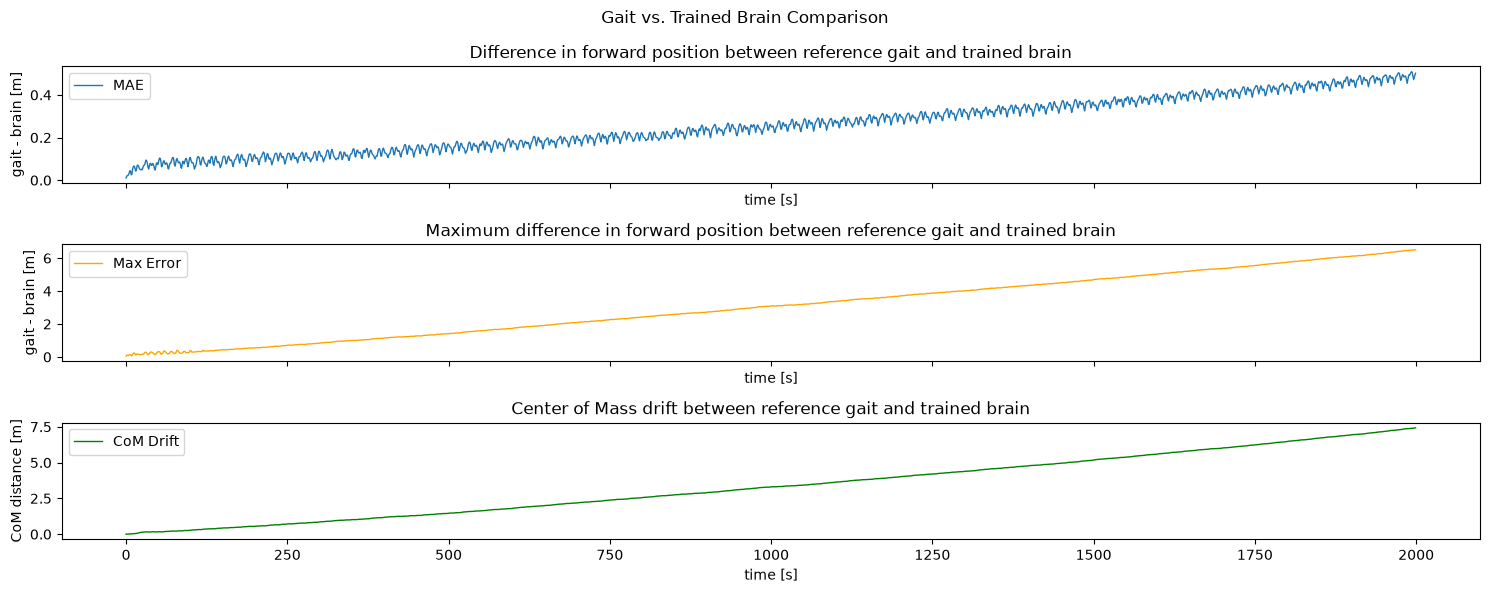

In [19]:
fig, ax = plt.subplots(3, 1, figsize=(15, 6), sharex=True)

ax[0].plot(mae_history, lw=1, label="MAE")
ax[0].set_xlabel("time [s]")
ax[0].set_ylabel("gait - brain [m]")
ax[0].set_title("Difference in forward position between reference gait and trained brain")
ax[0].legend()

ax[1].plot(max_error_history, lw=1, label="Max Error", color="orange")
ax[1].set_xlabel("time [s]")
ax[1].set_ylabel("gait - brain [m]")
ax[1].set_title("Maximum difference in forward position between reference gait and trained brain")
ax[1].legend()

ax[2].plot(com_drift_history, lw=1, label="CoM Drift", color="green")
ax[2].set_xlabel("time [s]")
ax[2].set_ylabel("CoM distance [m]")
ax[2].set_title("Center of Mass drift between reference gait and trained brain")
ax[2].legend()

plt.suptitle("Gait vs. Trained Brain Comparison")
plt.tight_layout()
plt.show()
